## Ćwiczenie 9: Analiza Widmowa (FFT) - Blok 1
**Cel:** Zrozumienie różnicy między dziedziną przestrzenną (piksele) a dziedziną częstotliwości (fale). Wykonanie pierwszej Transformaty Fouriera i zaprojektowanie podstawowego filtru dolnoprzepustowego.

#### Wprowadzenie teoretyczne
Każdy obraz medyczny można traktować jako sumę nakładających się na siebie fal (sinusoid) o różnej częstotliwości i kierunku.
* **Niskie częstotliwości (Środek widma):** Odpowiadają za ogólny rozkład jasności, tło i duże, gładkie kształty narządów.
* **Wysokie częstotliwości (Krawędzie widma):** Odpowiadają za gwałtowne zmiany jasności, ostre krawędzie, drobne detale oraz szum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color

plt.rcParams['figure.figsize'] = (12, 6)

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


#### Krok 1: Wczytanie obrazu medycznego
Wykorzystamy przekrój z rezonansu magnetycznego (MRI), który zawiera zarówno łagodne przejścia (tkanka), jak i bardzo ostre krawędzie (czaszka).

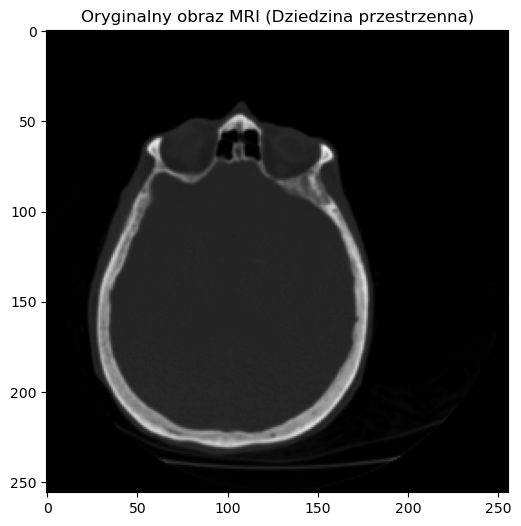

In [6]:
# Wczytujemy 8-my przekrój skanu MRI
mri_image = data.brain()[1, :, :]

plt.title('Oryginalny obraz MRI (Dziedzina przestrzenna)')
plt.imshow(mri_image, cmap='gray')
plt.show()

#### Krok 2: Przejście w dziedzinę częstotliwości (FFT)
**Zadanie:** Użyj biblioteki NumPy do obliczenia Dwuwymiarowej Transformaty Fouriera (`np.fft.fft2`), a następnie przesuń środek układu współrzędnych (`np.fft.fftshift`), aby zerowe częstotliwości znalazły się w centrum obrazu.

In [22]:
# WYKONAJ: Oblicz FFT2 i wykonaj przesunięcie (fftshift)
# === TWÓJ KÓD TUTAJ ===
fft_result = np.zeros_like(mri_image)      # <- Zastąp obliczeniem fft2 z mri_image
fft_shifted = np.zeros_like(fft_result)    # <- Zastąp przesunięciem fftshift
# ======================

# FFT zwraca liczby ZESPOLONE. Aby je wyświetlić, musimy wyciągnąć ich moduł (amplitudę).
# Ponadto dynamika wartości jest bardzo duża, konieczne jest więc użycie skali logarytmicznej, w przeciwnym razie zobaczymy tylko jeden biały punkt.

# WYKONAJ: Oblicz widmo amplitudowe z użyciem logarytmu
# === TWÓJ KÓD TUTAJ ===
magnitude_spectrum = np.zeros_like(mri_image) # <- Podmień na: np.log(1 + np.abs(fft_shifted))
# ======================

# plt.title('Widmo Amplitudowe (Dziedzina częstotliwości)')
# plt.imshow(magnitude_spectrum, cmap='gray')
# plt.show()

#### Krok 3: Eksperyment 1 – Filtr dolnoprzepustowy (Low-Pass Filter)
Sprawdźmy, co się stanie, gdy wytniemy (wyzerujemy) z widma wszystkie wysokie częstotliwości (pozostawiając tylko fale ze środka).

**Zadanie:** Przeanalizuj kod tworzący okrągłą maskę. Następnie wykonaj Odwrotną Transformatę Fouriera (`ifft2`), aby odzyskać obraz z odfiltrowanego widma.

In [25]:
# 1. Tworzymy siatkę współrzędnych i okrągłą maskę na środku obrazu
rows, cols = mri_image.shape
center_row, center_col = rows // 2, cols // 2

Y, X = np.ogrid[:rows, :cols]
distance_from_center = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# Zostawiamy tylko fale o promieniu mniejszym niż 30 pikseli od centrum
radius = 30
low_pass_mask = distance_from_center <= radius

# 2. Wymnażamy nasze widmo (fft_shifted) przez maskę - ucinamy brzegi widma
filtered_fft_shifted = fft_shifted * low_pass_mask

# WYKONAJ: Cofnij przesunięcie (ifftshift) i wykonaj Odwrotną Transformatę (ifft2)
# === TWÓJ KÓD TUTAJ ===
fft_ishift = np.zeros_like(filtered_fft_shifted)  # <- Podmień na np.fft.ifftshift z filtered_fft_shifted
image_reconstructed = np.zeros_like(mri_image)    # <- Podmień na np.fft.ifft2 z fft_ishift
# ======================

# Wyciągamy rzeczywistą część zrekonstruowanego obrazu (odrzucamy ewentualne ułamki zespolone z błędów numerycznych)
image_reconstructed = np.abs(image_reconstructed)

# --- WIZUALIZACJA --- 
# fig, axes = plt.subplots(1, 3, figsize=(15, 5))
# axes[0].imshow(low_pass_mask, cmap='gray')
# axes[0].set_title('Maska Filtru Dolnoprzepustowego')
# axes[1].imshow(np.log(1 + np.abs(filtered_fft_shifted)), cmap='gray')
# axes[1].set_title('Widmo po odcięciu wysokich fal')
# axes[2].imshow(image_reconstructed, cmap='gray')
# axes[2].set_title('Obraz po IFFT (Zauważ rozmycie!)')
# plt.tight_layout()
# plt.show()